In [3]:
import ast
from collections import Counter
import json
import re
import time
import warnings

from bs4 import BeautifulSoup
import folium
from googlesearch import search
from kiwipiepy import Kiwi
from konlpy.tag import Okt
import matplotlib
from matplotlib import font_manager, rc
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.experimental import enable_hist_gradient_boosting
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBClassifier
from xgboost import XGBRegressor
from lightgbm import LGBMClassifier
from lightgbm import LGBMRegressor
from wordcloud import WordCloud
from sklearn.datasets import fetch_olivetti_faces
from tensorflow.keras.datasets import cifar10
from sklearn.decomposition import PCA
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

plt.rcParams['axes.unicode_minus'] = False

# 경고 메시지 무시 설정
warnings.filterwarnings(action='ignore')

# 매직 명령어 및 소수점 설정
%precision 3
%matplotlib inline

# 한글 폰트 설정 (Windows 맑은 고딕)
font_path = "c:/Windows/fonts/malgun.ttf"
font_name = font_manager.FontProperties(fname=font_path).get_name()
matplotlib.rc('font', family=font_name)

c:\Users\smart\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\experimental\enable_hist_gradient_boosting.py:18: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


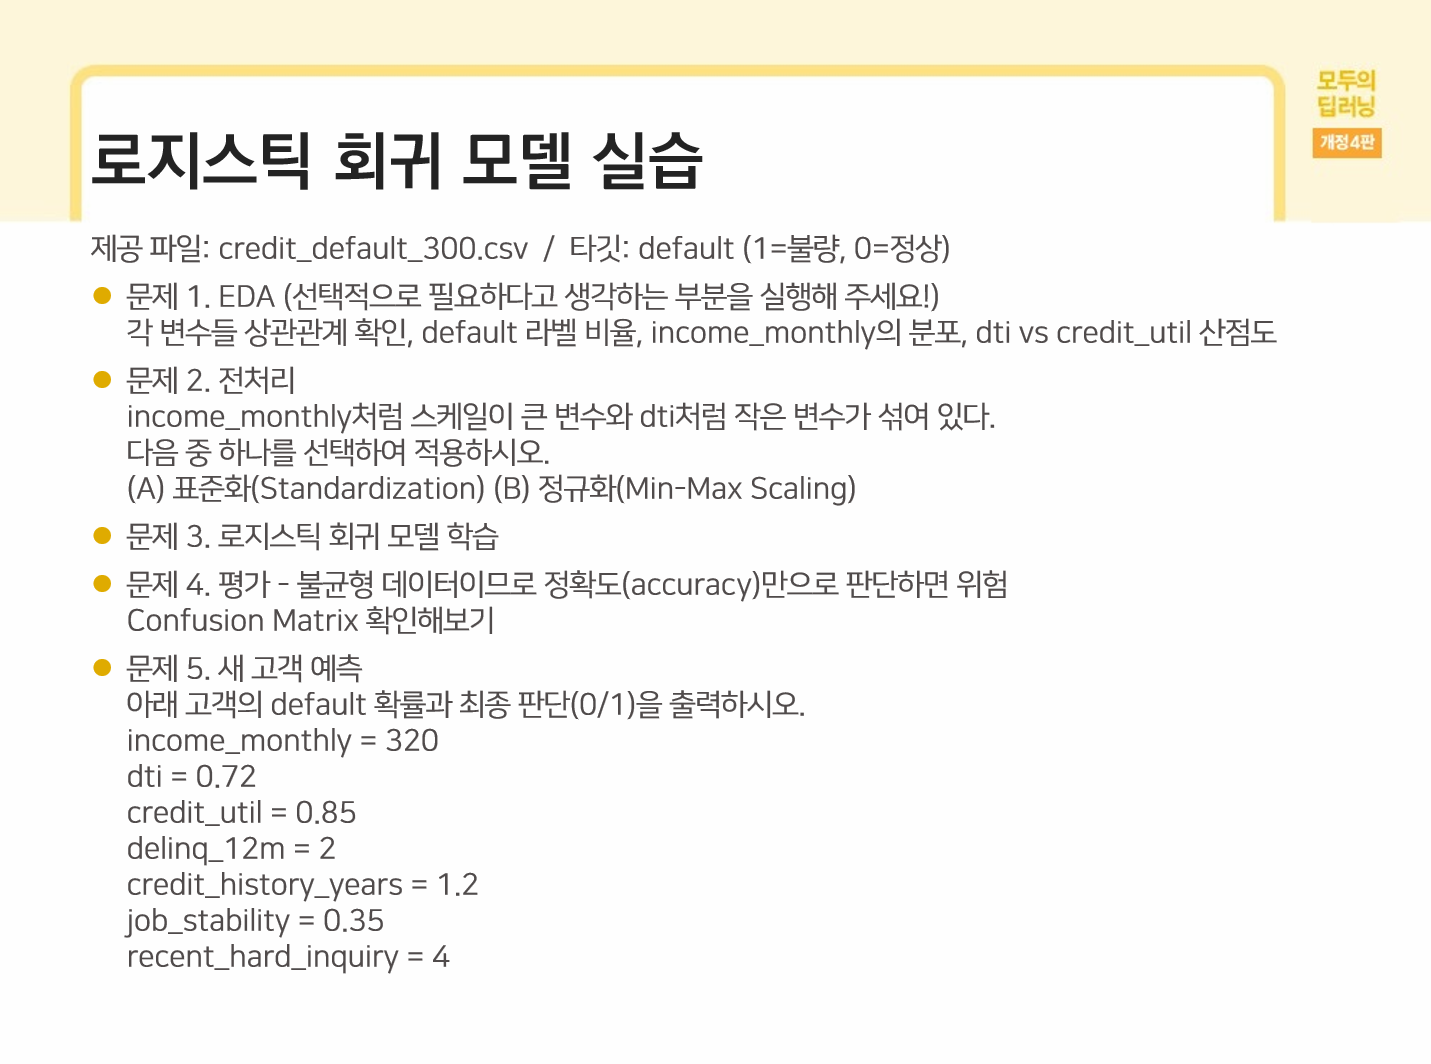

In [5]:
df = pd.read_csv('./credit_default_300.csv')

In [3]:
df.head()

,income_monthly,dti,credit_util,delinq_12m,credit_history_years,job_stability,recent_hard_inquiry,default
0,543.3,0.438,0.338,1,6.62,0.668,1,1
1,1148.3,0.217,0.890,0,6.54,0.112,1,0
2,918.6,0.391,0.315,0,11.84,0.391,2,0
3,778.6,0.397,0.093,0,6.72,0.464,3,0
4,313.8,0.732,0.700,0,1.93,0.574,1,1


In [6]:
print(df.shape)
print(df.isna().sum())
print(df.describe())

(300, 8)
income_monthly          0
dti                     0
credit_util             0
delinq_12m              0
credit_history_years    0
job_stability           0
recent_hard_inquiry     0
default                 0
dtype: int64
       income_monthly         dti  credit_util  delinq_12m  \
count      300.000000  300.000000   300.000000  300.000000   
mean       669.966667    0.480167     0.465620    0.626667   
std        309.058440    0.194467     0.225859    0.801726   
min        155.300000    0.050000     0.026000    0.000000   
25%        401.000000    0.344750     0.283250    0.000000   
50%        687.300000    0.476000     0.455000    0.000000   
75%        944.675000    0.623250     0.641250    1.000000   
max       1189.600000    0.942000     1.025000    4.000000   

       credit_history_years  job_stability  recent_hard_inquiry     default  
count            300.000000     300.000000           300.000000  300.000000  
mean               8.115633       0.524750             

In [9]:
print(df['default'].value_counts())

default
0    210
1     90
Name: count, dtype: int64


In [10]:
print(df['income_monthly'].describe())

count     300.000000
mean      669.966667
std       309.058440
min       155.300000
25%       401.000000
50%       687.300000
75%       944.675000
max      1189.600000
Name: income_monthly, dtype: float64


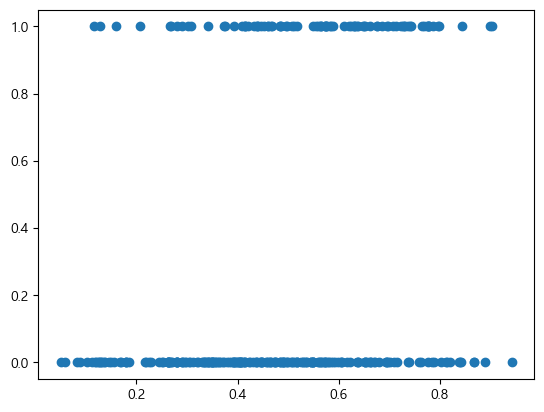

In [23]:
plt.scatter(df['dti'],df['default'])
plt.show()

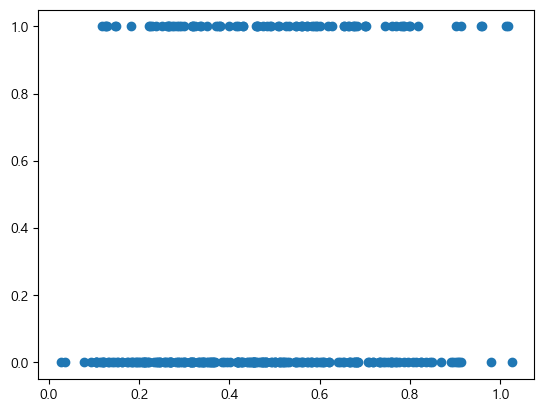

In [24]:
plt.scatter(df['credit_util'],df['default'])
plt.show()

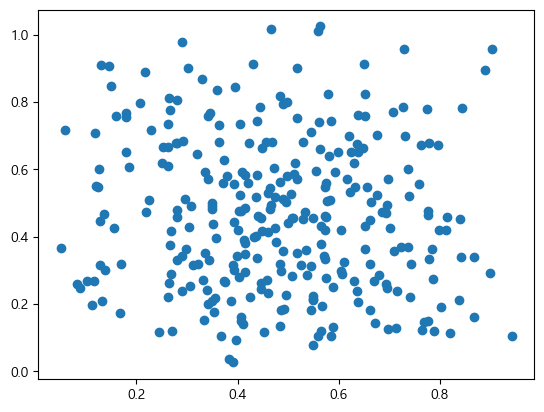

In [11]:
plt.scatter(df['dti'],df['credit_util'])
plt.show()

In [6]:
ss = StandardScaler()

df['s_income'] = ss.fit_transform(df[['income_monthly']])

In [14]:
df

,income_monthly,dti,credit_util,delinq_12m,credit_history_years,job_stability,recent_hard_inquiry,default,s_income
0,543.3,0.438,0.338,1,6.62,0.668,1,1,-0.410532
1,1148.3,0.217,0.890,0,6.54,0.112,1,0,1.550298
2,918.6,0.391,0.315,0,11.84,0.391,2,0,0.805831
3,778.6,0.397,0.093,0,6.72,0.464,3,0,0.352085
4,313.8,0.732,0.700,0,1.93,0.574,1,1,-1.154351
...,...,...,...,...,...,...,...,...,...
295,698.4,0.458,0.270,0,0.91,0.544,0,0,0.092154
296,958.5,0.103,0.268,0,7.53,0.814,2,0,0.935148
297,376.6,0.764,0.124,3,2.64,0.460,1,1,-0.950813
298,804.0,0.380,0.580,0,13.03,0.617,1,0,0.434407


In [9]:
y=df['default']

In [15]:
model = Sequential()
model.add(Dense(1, input_dim=1, activation='sigmoid'))

# 교차 엔트로피 오차 함수를 이용하기 위하여 'binary_crossentropy'로 설정합니다. 
model.compile(optimizer='sgd' ,loss='binary_crossentropy')

model.fit(df['s_income'], df['default'], epochs=1000)

Epoch 1/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8462  
Epoch 2/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.8338 
Epoch 3/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8222 
Epoch 4/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8112 
Epoch 5/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8002 
Epoch 6/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7890 
Epoch 7/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7785 
Epoch 8/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7688 
Epoch 9/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7598 
Epoch 10/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7511 
Epoch 11/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7422 
Epoch 12/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7345 
Epoch 13/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.7268
Epoch 14/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7200 
Epoch 15/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


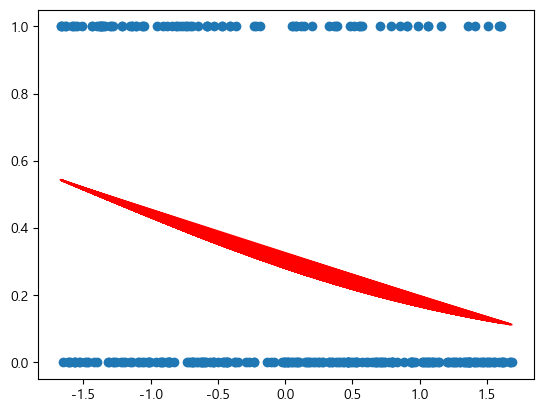

In [17]:
#그래프로 확인해 봅니다.

plt.scatter(df['s_income'],y )
plt.plot(df['s_income'], model.predict(df['s_income']),'r')
plt.show()

In [19]:
df.head(0)

,income_monthly,dti,credit_util,delinq_12m,credit_history_years,job_stability,recent_hard_inquiry,default,s_income


In [25]:
model = Sequential()
model.add(Dense(1, input_dim=1, activation='sigmoid'))

# 교차 엔트로피 오차 함수를 이용하기 위하여 'binary_crossentropy'로 설정합니다. 
model.compile(optimizer='sgd' ,loss='binary_crossentropy')

model.fit(df['credit_util'], df['default'], epochs=1000)

Epoch 1/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6411 
Epoch 2/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6406 
Epoch 3/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6401 
Epoch 4/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.6397 
Epoch 5/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6392 
Epoch 6/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6388
Epoch 7/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6384
Epoch 8/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6380 
Epoch 9/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6376 
Epoch 10/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6373 
Epoch 11/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6369 
Epoch 12/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6366 
Epoch 13/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6363 
Epoch 14/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6361 
Epoch 15/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


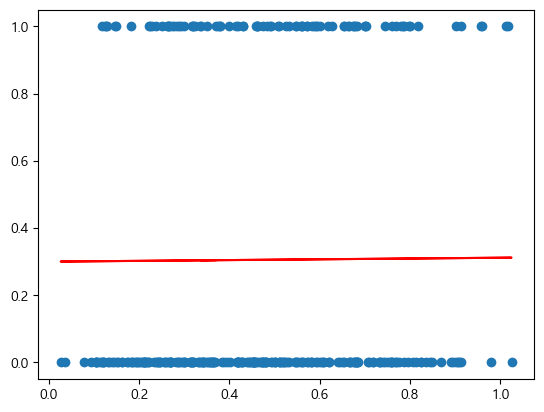

In [26]:
#그래프로 확인해 봅니다.

plt.scatter(df['credit_util'],y )
plt.plot(df['credit_util'], model.predict(df['credit_util']),'r')
plt.show()

In [7]:
model = Sequential()
model.add(Dense(1, input_dim=1, activation='sigmoid'))

# 교차 엔트로피 오차 함수를 이용하기 위하여 'binary_crossentropy'로 설정합니다. 
model.compile(optimizer='sgd' ,loss='binary_crossentropy')

model.fit(df['dti'], df['default'], epochs=1000)

Epoch 1/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6538  
Epoch 2/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.6532 
Epoch 3/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 701us/step - loss: 0.6525
Epoch 4/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6518 
Epoch 5/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6512 
Epoch 6/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6507 
Epoch 7/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6502 
Epoch 8/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6497 
Epoch 9/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6493
Epoch 10/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6488 
Epoch 11/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6485 
Epoch 12/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6480 
Epoch 13/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6476 
Epoch 14/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6472 
Epoch 15/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


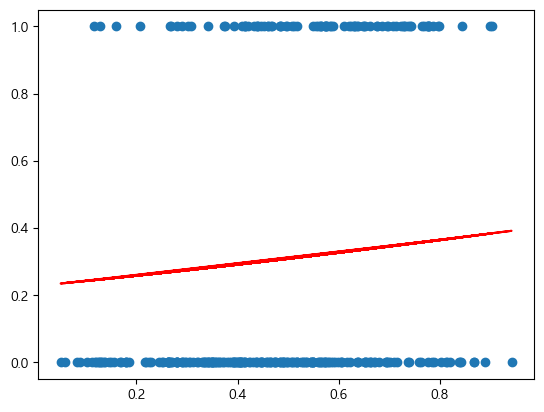

In [10]:
#그래프로 확인해 봅니다.

plt.scatter(df['dti'],y )
plt.plot(df['dti'], model.predict(df['dti']),'r')
plt.show()

In [11]:
import tensorflow as tf
print("현재 TensorFlow 버전:", tf.__version__)

dti = 0.2
input_data = tf.constant([[dti]], dtype=tf.float32) 
prediction = model.predict(input_data)[0][0]  


print("부채비율이 %.01f%% 일때 부도 낼 확률이 %.01f%%입니다" % (dti,prediction * 100))

현재 TensorFlow 버전: 2.21.0
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
부채비율이 0.2% 일때 부도 낼 확률이 25.8%입니다


In [28]:
df.head(2)

,income_monthly,dti,credit_util,delinq_12m,credit_history_years,job_stability,recent_hard_inquiry,default,s_income
0,543.3,0.438,0.338,1,6.62,0.668,1,1,-0.410532
1,1148.3,0.217,0.890,0,6.54,0.112,1,0,1.550298


In [ ]:
y_pred_prob = model.predict(df['dti'])
#0.5 이상으로 나오는값들은 default값에 맞춰서 1로 바꾸어주고 
#0.5 아래로 나오는 값들은 0으로 내려주었다.
y_pred = (y_pred_prob >= 0.5).astype(int)

accuracy = accuracy_score(y, y_pred)
error_rate = 1 - accuracy

print(f"정확도: {accuracy * 100:.2f}%")
print(f"오차율: {error_rate * 100:.2f}%")

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
정확도: 70.00%
오차율: 30.00%


In [ ]:
pred = model.predict(df['dti'])
y_pred = (pred >= 0.5).astype(int)
cm = confusion_matrix(df['default'], y_pred)
print(cm)
#0일때 0을 맞춘값이 210, 1일때 0으로 답한 값이 90개로
#90/300 하면 30프로이므로 위의 정확도 계산과 맞는것을 확인하였다.

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
[[210   0]
 [ 90   0]]


In [17]:
#마지막으로 모든 컬럼을 x로 하여 모델을 돌려주겠다.
x=df.drop(columns=['default','income_monthly'])
x.columns

Index(['dti', 'credit_util', 'delinq_12m', 'credit_history_years',
       'job_stability', 'recent_hard_inquiry', 's_income'],
      dtype='object')

In [18]:
model = Sequential()
model.add(Dense(1, input_dim=7, activation='sigmoid'))

# 교차 엔트로피 오차 함수를 이용하기 위하여 'binary_crossentropy'로 설정합니다. 
model.compile(optimizer='sgd' ,loss='binary_crossentropy')

model.fit(x, df['default'], epochs=1000)

Epoch 1/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9813  
Epoch 2/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8102 
Epoch 3/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7975 
Epoch 4/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7930 
Epoch 5/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7798 
Epoch 6/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7713 
Epoch 7/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7622 
Epoch 8/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.7521 
Epoch 9/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 979us/step - loss: 0.7454
Epoch 10/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7342 
Epoch 11/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7281 
Epoch 12/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7211 
Epoch 13/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7167 
Epoch 14/1000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 755us/step - loss: 0.7100
Epoch 15/1000
10/10 ━━━━━━━━━━━━━━━━━━━━

In [20]:
income_monthly=320
dti=0.72
credit_util=0.85
delinq_12m =2
credit_history_years=1.2
job_stability=0.35
recent_hard_inquiry=4
#표준화 해준값을 집어넣기위해서
s_income = float(ss.transform([[income_monthly]])[0][0])
input_data = np.array([[
    dti, credit_util, delinq_12m, credit_history_years, job_stability, recent_hard_inquiry, s_income
]], dtype=np.float32)
prediction = model.predict(input_data)[0][0]  


print("%.01f%% 입니다" % (prediction * 100))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
97.4% 입니다
